In [48]:

import io

path = "/content/chronic_kidney_disease_full.arff"

with open(path, encoding="utf-8", errors="ignore") as f:
    lines = [l.strip() for l in f.read().splitlines()]


cols = [l.split("'")[1] for l in lines if l.lower().startswith("@attribute")]


start = [i for i, l in enumerate(lines) if l.lower() == "@data"][0]
rows = [l for l in lines[start + 1:] if l and not l.startswith("%")]


fixed = []
for r in rows:
    parts = [p.strip() for p in r.split(",")]
    if len(parts) > len(cols):
        parts = [p for p in parts if p != ""]
    fixed.append(",".join(parts))





In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [50]:
df = pd.read_csv(io.StringIO("\n".join(fixed)), names=cols, na_values="?",)

In [51]:
df.head(10)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd
5,60.0,90.0,1.015,3.0,0.0,NaN,NaN,notpresent,notpresent,74.0,...,39.0,7800.0,4.4,yes,yes,no,good,yes,no,ckd
6,68.0,70.0,1.010,0.0,0.0,NaN,normal,notpresent,notpresent,100.0,...,36.0,NaN,NaN,no,no,no,good,no,no,ckd
7,24.0,NaN,1.015,2.0,4.0,normal,abnormal,notpresent,notpresent,410.0,...,44.0,6900.0,5.0,no,yes,no,good,yes,no,ckd
8,52.0,100.0,1.015,3.0,0.0,normal,abnormal,present,notpresent,138.0,...,33.0,9600.0,4.0,yes,yes,no,good,no,yes,ckd
9,53.0,90.0,1.020,2.0,0.0,abnormal,abnormal,present,notpresent,70.0,...,29.0,12100.0,3.7,yes,yes,no,poor,no,yes,ckd


In [52]:
print(f"Number of rows : {df.shape[0]}")
print(f"Number of columns : {df.shape[1]}")

Number of rows : 400
Number of columns : 25


# check  duplicates

In [53]:
print(f"Total duplicates :{df.duplicated().sum()}")

Total duplicates :0


# Check The missing Values per columns

In [54]:
missing_values = pd.DataFrame({
    "Total_missing":df.isna().sum(),
    "missing_percent":round(df.isna().mean()*100,1)


}).sort_values('missing_percent', ascending = False)
missing_values

,Total_missing,missing_percent
rbc,152,38.0
rbcc,131,32.8
wbcc,106,26.5
pot,88,22.0
sod,87,21.8
pcv,71,17.8
pc,65,16.2
hemo,52,13.0
su,49,12.2
sg,47,11.8


#Checking All The DataType

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    object 
 6   pc      335 non-null    object 
 7   pcc     396 non-null    object 
 8   ba      396 non-null    object 
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    object 
 19  dm      398 non-null    object 
 20  cad     398 non-null    object 
 21  appet   399 non-null    object 
 22  pe

In [56]:
df['class'].value_counts(normalize=True)*100

,proportion
class,
ckd,62.5
notckd,37.5


# check categorical columns unique values

In [57]:
cat_col = df.select_dtypes(include = 'object').columns.tolist()
print(f"All categorical columns : {cat_col}")
for col in cat_col:
  print(f"{col}: { df[col].unique()}")

All categorical columns : ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']
rbc: [nan 'normal' 'abnormal']
pc: ['normal' 'abnormal' nan]
pcc: ['notpresent' 'present' nan]
ba: ['notpresent' 'present' nan]
htn: ['yes' 'no' nan]
dm: ['yes' 'no' nan]
cad: ['no' 'yes' nan]
appet: ['good' 'poor' nan]
pe: ['no' 'yes' nan]
ane: ['no' 'yes' nan]
class: ['ckd' 'notckd']


# In rbc(red blood cell )the number of missing values are huge which is serious case

In [58]:
for col in cat_col:
  print(f"--------{col}-----------------")
  print(df[col].value_counts(dropna = False))

--------rbc-----------------
rbc
normal      201
NaN         152
abnormal     47
Name: count, dtype: int64
--------pc-----------------
pc
normal      259
abnormal     76
NaN          65
Name: count, dtype: int64
--------pcc-----------------
pcc
notpresent    354
present        42
NaN             4
Name: count, dtype: int64
--------ba-----------------
ba
notpresent    374
present        22
NaN             4
Name: count, dtype: int64
--------htn-----------------
htn
no     251
yes    147
NaN      2
Name: count, dtype: int64
--------dm-----------------
dm
no     261
yes    137
NaN      2
Name: count, dtype: int64
--------cad-----------------
cad
no     364
yes     34
NaN      2
Name: count, dtype: int64
--------appet-----------------
appet
good    317
poor     82
NaN       1
Name: count, dtype: int64
--------pe-----------------
pe
no     323
yes     76
NaN      1
Name: count, dtype: int64
--------ane-----------------
ane
no     339
yes     60
NaN      1
Name: count, dtype: int64
--------c

In [59]:
for col in ['sg','al','su']:
  print(f"-----------{col}----------------")
  print(df[col].value_counts(dropna = False))

-----------sg----------------
sg
1.020    106
1.010     84
1.025     81
1.015     75
NaN       47
1.005      7
Name: count, dtype: int64
-----------al----------------
al
0.0    199
NaN     46
1.0     44
3.0     43
2.0     43
4.0     24
5.0      1
Name: count, dtype: int64
-----------su----------------
su
0.0    290
NaN     49
2.0     18
3.0     14
4.0     13
1.0     13
5.0      3
Name: count, dtype: int64


<Axes: >

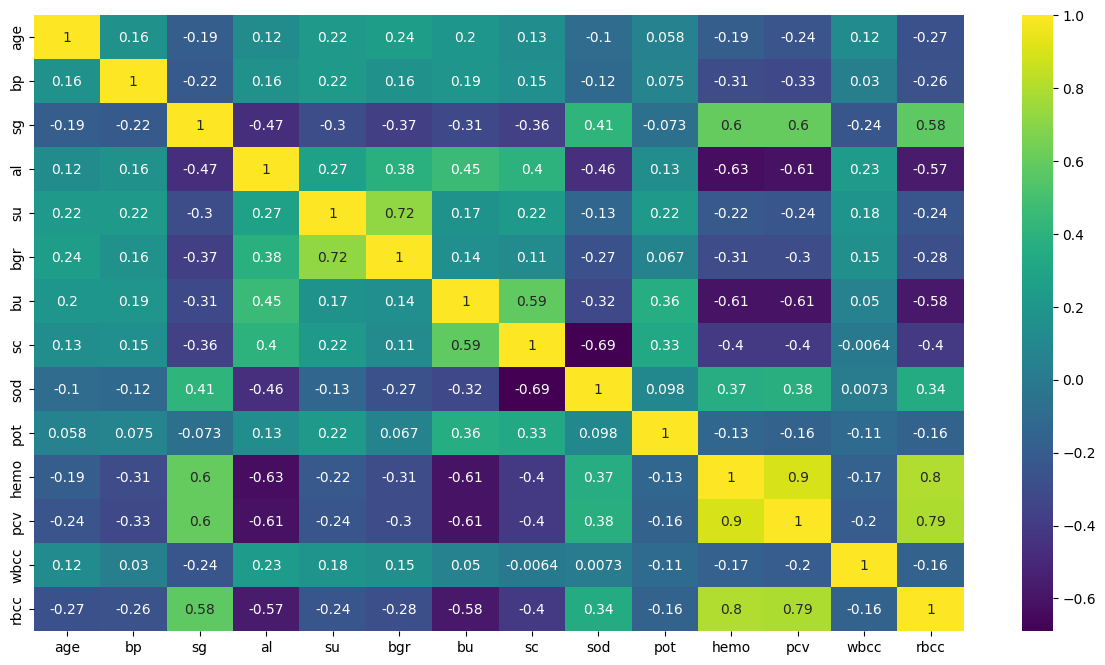

In [60]:
plt.figure(figsize=(15,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap = 'viridis')

# Statistical Overveiw

In [61]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,391.0,51.483376,17.169714,2.000,42.00,55.00,64.50,90.000
bp,388.0,76.469072,13.683637,50.000,70.00,80.00,80.00,180.000
sg,353.0,1.017408,0.005717,1.005,1.01,1.02,1.02,1.025
al,354.0,1.016949,1.352679,0.000,0.00,0.00,2.00,5.000
su,351.0,0.450142,1.099191,0.000,0.00,0.00,0.00,5.000
bgr,356.0,148.036517,79.281714,22.000,99.00,121.00,163.00,490.000
bu,381.0,57.425722,50.503006,1.500,27.00,42.00,66.00,391.000
sc,383.0,3.072454,5.741126,0.400,0.90,1.30,2.80,76.000
sod,313.0,137.528754,10.408752,4.500,135.00,138.00,142.00,163.000
pot,312.0,4.627244,3.193904,2.500,3.80,4.40,4.90,47.000


# Perform The EDA

In [62]:
num_cols = ["age","bp","bgr","bu","sc","sod","pot","hemo","pcv","wbcc","rbcc"]
ord_cols = ["sg","al","su"]
len(num_cols)

11

# compair target column with numerical columns
- here in age column has enough outlires. column sc , bu ,bgr also have large   number of outliers .


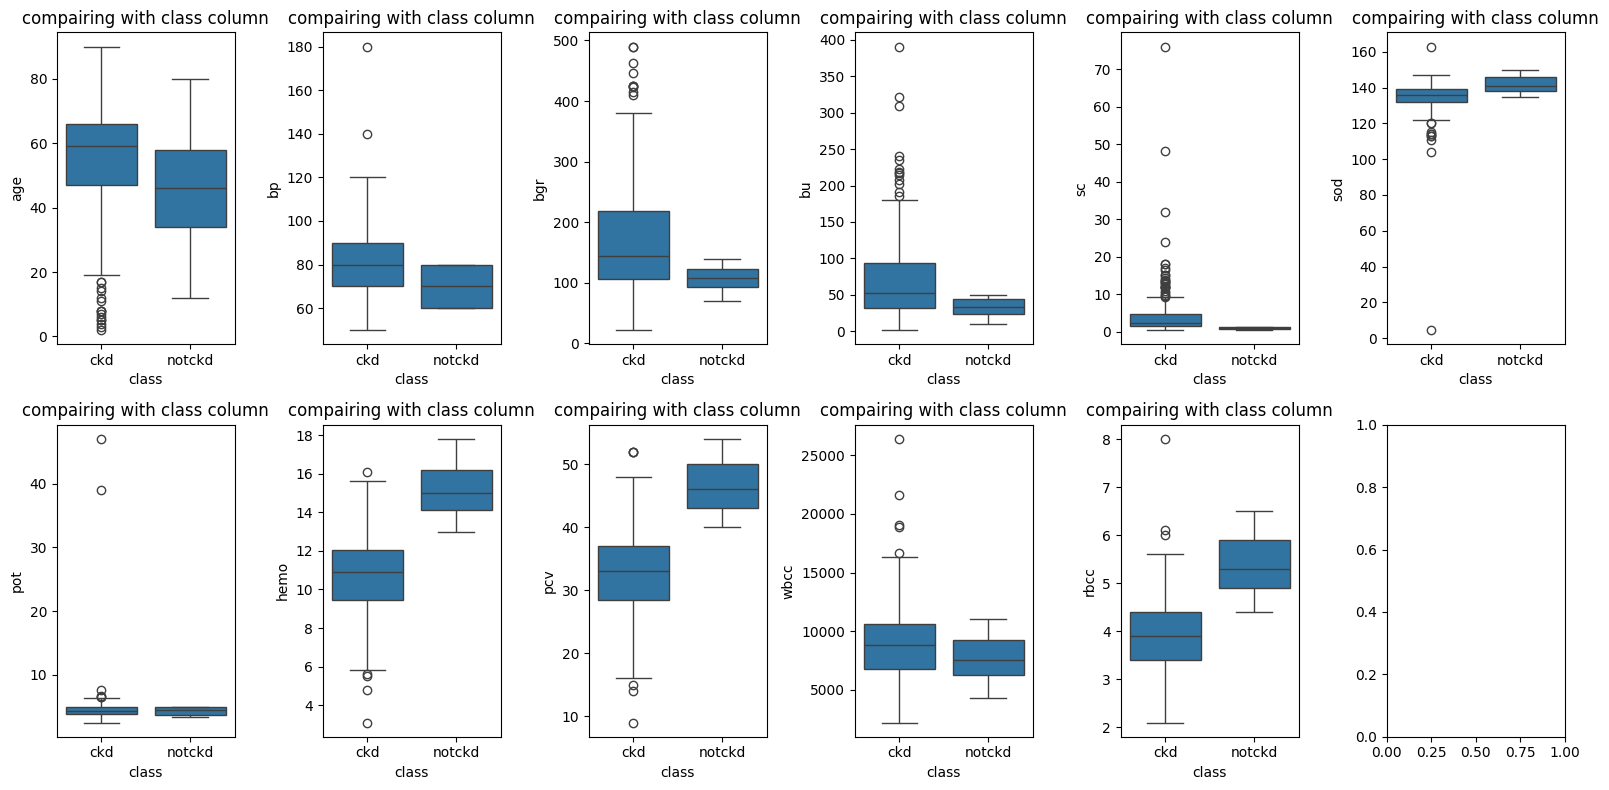

In [63]:
fig , axis = plt.subplots(ncols =6,nrows = 2 ,figsize=(16,8))
axis = axis.flatten()
for i ,col in enumerate(num_cols):
  sns.boxplot(data = df , ax =axis[i],x = 'class',y = col)
  axis[i].set_title("compairing with class column")
plt.tight_layout()
plt.savefig("box_plots.png", dpi = 150)
plt.show()


In [64]:
cat_col

['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']

# categorical columns vs class column
**Result**
- those patients who has no ckd(cronic kidney deaseas) also they have no htn and dm  
- rbc(red blood cell) is high in non ckd(cronic kidney disease) patients
-  pcc nad cad  is so low those patients who has ckd(cronic kidney
disease)


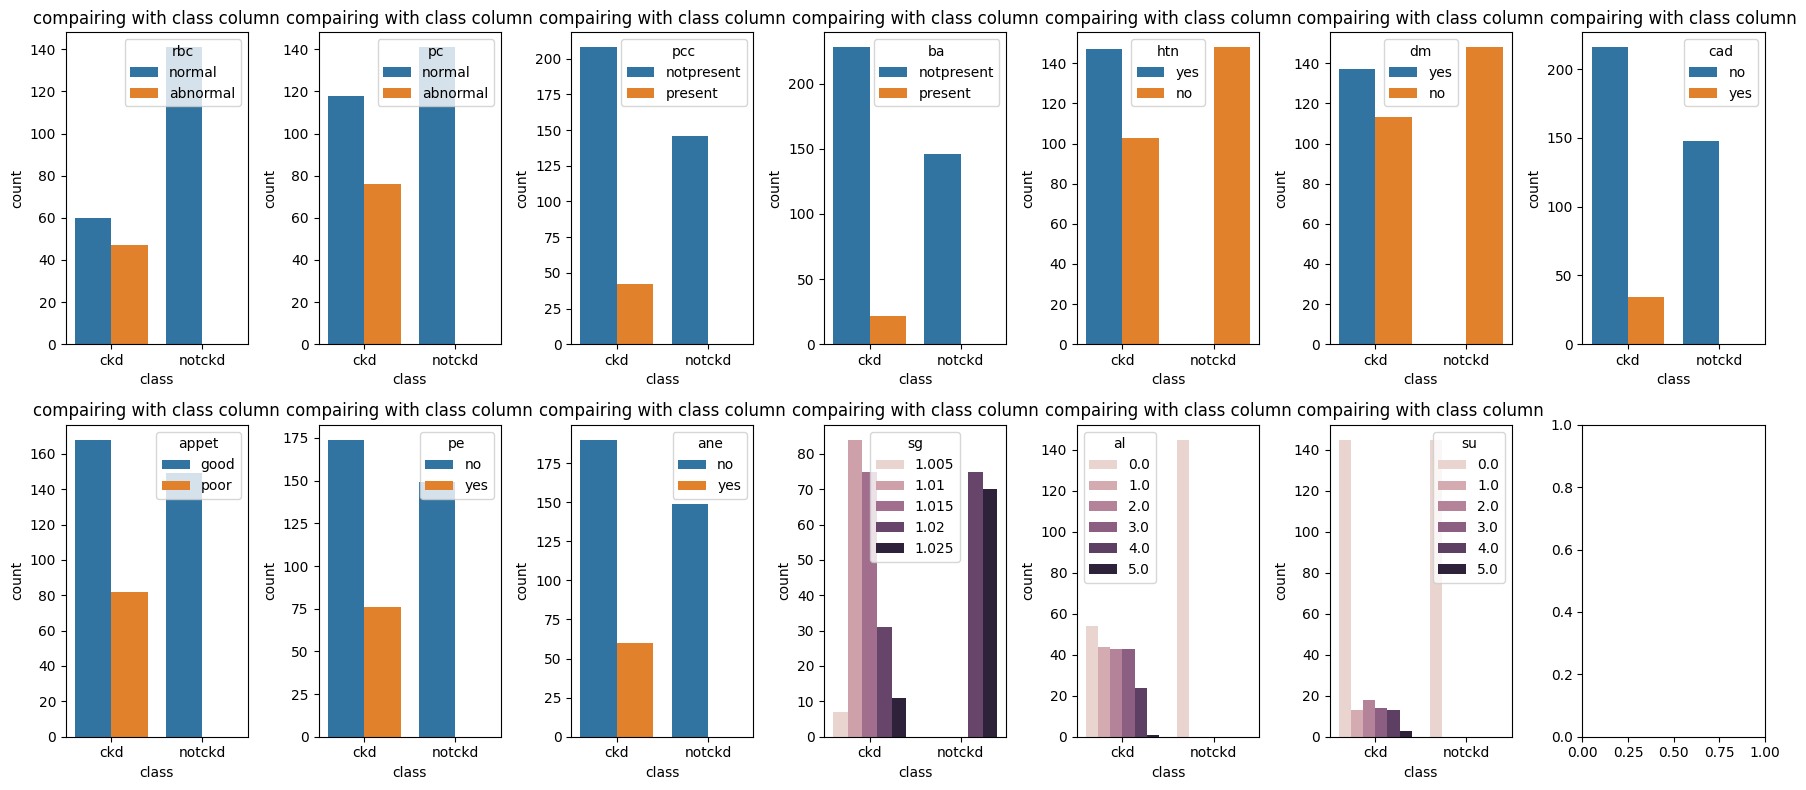

In [65]:
cols = cat_col[:-1] + ord_cols
fig , axis = plt.subplots(ncols =7,nrows = 2 ,figsize=(18,8))
axis = axis.flatten()
for i ,col in enumerate(cols):
  sns.countplot(data = df , ax =axis[i],x = 'class',hue = col)
  axis[i].set_title("compairing with class column")
plt.tight_layout()
plt.savefig("count_plots.png", dpi = 150)
plt.show()


#correlation between numerical columns

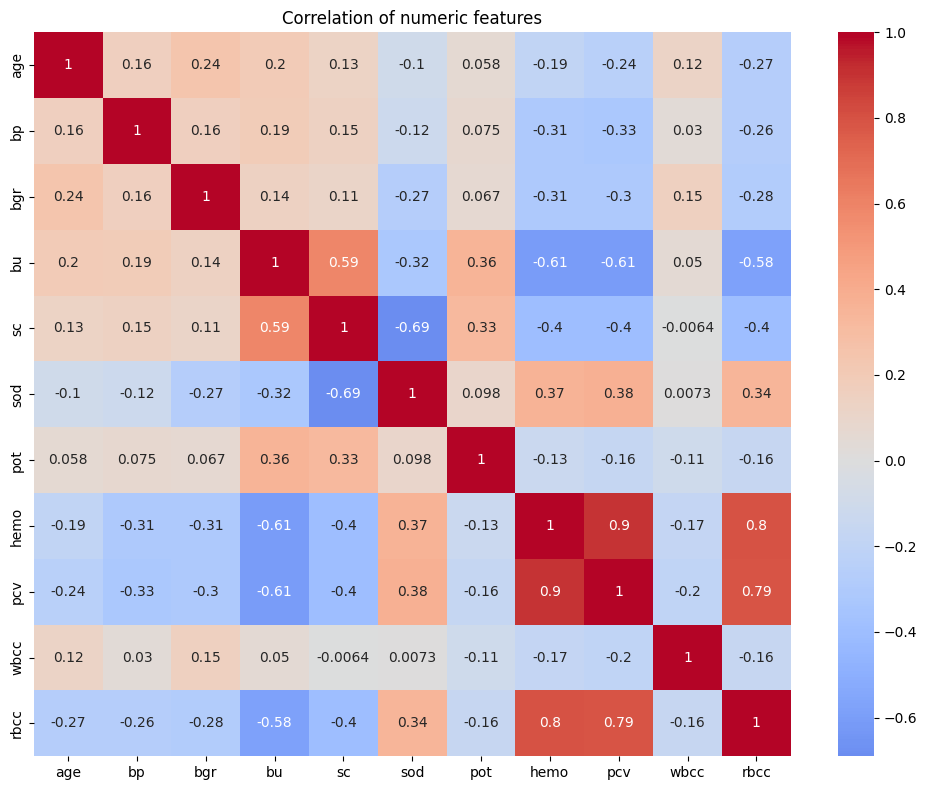

In [66]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True,  cmap="coolwarm" , center = 0)
plt.title("Correlation of numeric features")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=150)
plt.tight_layout()
plt.show()

**Analysis:**
- hemoglobin and packed cell volumn has higher correlation 90%
- hemoglobin and rbcc has also higher correlation 80%
- rbcc and packed cell volumn has also higher correlations

# check correlation with target column

In [67]:
result = df['class'].map({'ckd':1 , 'notckd':0})
df[num_cols].corrwith(result).sort_values(key = abs ,ascending=False).round(2)

,0
hemo,-0.77
pcv,-0.74
rbcc,-0.70
bgr,0.42
bu,0.38
sod,-0.38
sc,0.30
bp,0.29
wbcc,0.23
age,0.23


# Train - Test splitting

In [68]:
data = df.copy()

In [69]:
from sklearn.model_selection import train_test_split
x = data.drop('class', axis = 1)
y = result
X_train , X_test , y_train, y_test = train_test_split(x,y,test_size = 0.2,random_state=42,stratify=y)
print(f"Training data shape : {X_train.shape} , Testing data shape : {X_test.shape}")

Training data shape : (320, 24) , Testing data shape : (80, 24)


# creat pipelines

In [70]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
numeric_pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
 ('scaler',StandardScaler())])

cat_pipe = Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
 ('one_hot',OneHotEncoder(handle_unknown ="ignore", drop = 'first'))])

sg_levels = [1.005, 1.010, 1.015, 1.020, 1.025]
al_levels = [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
su_levels = [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]

ord_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
('ordinal',OrdinalEncoder(categories=[sg_levels,al_levels,su_levels],  handle_unknown='use_encoded_value',
        unknown_value=-1)),('scaler',StandardScaler())])

preprocess = ColumnTransformer(transformers=[('numeric_pipe', numeric_pipe,num_cols),
 ('cate_pipe',cat_pipe,cat_col[:-1]),("ordinal_pipe",ord_pipe,ord_cols)],remainder ='passthrough')


In [71]:
num_cols
cat_col

['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']

In [72]:
X_train_p = preprocess.fit_transform(X_train)
X_test_p = preprocess.transform(X_test)

#checking have any missing value yet or not

In [73]:
print(f"After Imputing X_train null :{np.isnan(X_train_p).sum()} , X_test null  {np.isnan(X_test_p).sum()}")

print(f"training : {X_train_p.shape} testing {X_test_p.shape}")

After Imputing X_train null :0 , X_test null  0
training : (320, 24) testing (80, 24)


#Model Part

In [74]:

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection  import cross_val_score
from sklearn.metrics import accuracy_score ,f1_score,recall_score,confusion_matrix,roc_auc_score,roc_curve
pipe_lr = Pipeline([('preprocess',preprocess),
                    ("model",LogisticRegression(max_iter=1000))])
score_lr1 = cross_val_score(pipe_lr,X_train , y_train , cv = 5 , scoring = 'accuracy').mean().round(2)
score_lr2 = cross_val_score(pipe_lr,X_train , y_train , cv = 5, scoring = 'f1').mean().round(2)
score_lr3 = cross_val_score(pipe_lr,X_train , y_train , cv = 5, scoring = 'recall').mean().round(2)
score_lr4= cross_val_score(pipe_lr,X_train , y_train , cv = 5, scoring = 'roc_auc').mean().round(2)
print(f"Accuracy score of Logisticregression: {score_lr1}")
print(f"f1_score of Logisticregression: {score_lr2}")
print(f"recall_score of Logisticregression: {score_lr3}")
print(f"roc_score of Logisticregression: {score_lr4}")




Accuracy score of Logisticregression: 0.99
f1_score of Logisticregression: 0.99
recall_score of Logisticregression: 0.99
roc_score of Logisticregression: 1.0


In [75]:
from sklearn.neighbors import KNeighborsClassifier
pipe_kn = Pipeline([('preprocess',preprocess),
                    ("model",KNeighborsClassifier(n_neighbors=5))])
score_kn1 = cross_val_score(pipe_kn,X_train , y_train , cv = 5 , scoring = 'accuracy').mean().round(2)
score_kn2 = cross_val_score(pipe_kn,X_train , y_train , cv = 5, scoring = 'f1').mean().round(2)
score_kn3 = cross_val_score(pipe_kn,X_train , y_train , cv = 5, scoring = 'recall').mean().round(2)
score_kn4= cross_val_score(pipe_kn,X_train , y_train , cv = 5, scoring = 'roc_auc').mean().round(2)
print(f"Accuracy score of KNN: {score_kn1}")
print(f"f1_score of KNN: {score_kn2}")
print(f"recall_score of KNN : {score_kn3}")
print(f"roc_score of KNN: {score_kn4}")

Accuracy score of KNN: 0.97
f1_score of KNN: 0.97
recall_score of KNN : 0.94
roc_score of KNN: 0.99


In [76]:
from sklearn.ensemble import RandomForestClassifier
pipe_rf= Pipeline([('preprocess',preprocess),
                    ("model",RandomForestClassifier(n_estimators=500))])
score_rf1 = cross_val_score(pipe_rf,X_train , y_train , cv = 5 , scoring = 'accuracy').mean().round(2)
score_rf2 = cross_val_score(pipe_rf,X_train , y_train , cv = 5, scoring = 'f1').mean().round(2)
score_rf3 = cross_val_score(pipe_rf,X_train , y_train , cv = 5, scoring = 'recall').mean().round(2)
score_rf4= cross_val_score(pipe_rf,X_train , y_train , cv = 5, scoring = 'roc_auc').mean().round(2)
print(f"Accuracy score of RandomForestClassifier: {score_rf1}")
print(f"f1_score of RandomForestClassifier: {score_rf2}")
print(f"recall_score of RandomForestClassifier: {score_rf3}")
print(f"roc_score of RandomForestClassifier: {score_rf4}")

Accuracy score of RandomForestClassifier: 0.99
f1_score of RandomForestClassifier: 0.99
recall_score of RandomForestClassifier: 0.99
roc_score of RandomForestClassifier: 1.0


#Decision Period:
**Though Logistic Regression and Random Forest Classifier both result is same**
**i choose Random Forest Classifier as my Final Prediction Model**

In [77]:
pipe_rf = Pipeline([('preprocess',preprocess),('model',RandomForestClassifier(n_estimators=500,max_depth=3))])
pipe_rf.fit(X_train,y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('numeric_pipe',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bp', 'bgr', 'bu',
                                                   'sc', 'sod', 'pot', 'hemo',
                                                   'pcv', 'wbcc', 'rbcc']),
                                                 ('cate_pipe',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('one_hot...
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ordinal',
                                                                   OrdinalEncoder(categories=[[1.005,
                                                                                               1.01,
                                                                                               1.015,
                                                                                               1.02,
                                                                                               1.025],
                                                                                              [0.0,
                                                                                               1.0,
                                                                                               2.0,
                                                                                               3.0,
                                                                                               4.0,
                                                                                               5.0],
                                                                                              [0.0,
                                                                                               1.0,
                                                                                               2.0,
                                                                                               3.0,
                                                                                               4.0,
                                                                                               5.0]],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['sg', 'al', 'su'])])),
                ('model',
                 RandomForestClassifier(max_depth=3, n_estimators=500))])

In [78]:
y_pred = pipe_rf.predict(X_test)
accuracy_scores = accuracy_score(y_test , y_pred)
f1_scores = f1_score(y_test ,y_pred )
recall_scores = recall_score(y_test , y_pred)
roc_auc_scores = roc_auc_score(y_test , y_pred)
conf_matrixs = confusion_matrix(y_test , y_pred)

#Final Model Scoring

In [79]:
print(f"Final Accuracy score of RandomForestClassifier: {accuracy_scores}")
print(f"Final f1_score of RandomForestClassifier: {f1_scores}")
print(f"Final recall_score of RandomForestClassifier: {recall_scores}")
print(f"Final roc_score of RandomForestClassifier: {roc_auc_scores}")



Final Accuracy score of RandomForestClassifier: 0.9875
Final f1_score of RandomForestClassifier: 0.9900990099009901
Final recall_score of RandomForestClassifier: 1.0
Final roc_score of RandomForestClassifier: 0.9833333333333334


In [80]:
print(f"Final model confusion matrics :")
conf_matrixs

Final model confusion matrics :


array([[29,  1],
       [ 0, 50]])

In [81]:
y_pred_train = pipe_rf.predict(X_train)

In [82]:
accuracy_scores_train = accuracy_score(y_train, y_pred_train)
f1_scores_train = f1_score(y_train ,y_pred_train )
recall_scores_train = recall_score(y_train , y_pred_train)
roc_auc_scores_train = roc_auc_score(y_train , y_pred_train)
conf_matrixs_train = confusion_matrix(y_train , y_pred_train)

# Overfitting checking

In [83]:
print(f"Training Accuracy score of RandomForestClassifier: {accuracy_scores_train}")
print(f"Training f1_score of RandomForestClassifier: {f1_scores_train}")
print(f"Training recall_score of RandomForestClassifier: {recall_scores_train}")
print(f"Training roc_score of RandomForestClassifier: {roc_auc_scores_train}")


Training Accuracy score of RandomForestClassifier: 0.99375
Training f1_score of RandomForestClassifier: 0.9950248756218906
Training recall_score of RandomForestClassifier: 1.0
Training roc_score of RandomForestClassifier: 0.9916666666666666


# So , No overfitting

In [84]:
print("train score", pipe_rf.score(X_train , y_train))
print("test score", pipe_rf.score(X_test ,y_test))

train score 0.99375
test score 0.9875
